# Semantic Graph Construction

## 1. Introduction

This notebook aims to construct a semantic graph from the knowledge extracted during the previous data mining stages.

The graph will represent relationships between:

- Clinical features
- Association rules
- Clustering results
- Pathology categories

The objective is to provide a structured representation of the discovered knowledge and facilitate its exploration and visualization.

## 2. Importing Libraries

Import the libraries required for graph construction and visualization.

In [75]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Loading Knowledge Sources

Load the results generated during the previous data mining stages.

These results will serve as the knowledge sources for semantic graph construction.

In [76]:
# Load original datasets
mass_df = pd.read_csv("../data/mass_case_description_train_set.csv")
calc_df = pd.read_csv("../data/calc_case_description_train_set.csv")

# Load clustering results
mass_clusters = np.load("../data/processed/mass_clusters.npy")
calc_clusters = np.load("../data/processed/calc_clusters.npy")

# Load patient IDs
mass_patient_train = np.load(
    "../data/processed/mass_patient_train.npy",
    allow_pickle=True
)

calc_patient_train = np.load(
    "../data/processed/calc_patient_train.npy",
    allow_pickle=True
)

# Load original training row indices
mass_train_idx = np.load("../data/processed/mass_train_idx.npy")
calc_train_idx = np.load("../data/processed/calc_train_idx.npy")

print("Mass dataset:", mass_df.shape)
print("Calcification dataset:", calc_df.shape)

print("Mass clusters:", mass_clusters.shape)
print("Calcification clusters:", calc_clusters.shape)

print("Mass patient IDs:", mass_patient_train.shape)
print("Calcification patient IDs:", calc_patient_train.shape)

print("Mass training indices:", mass_train_idx.shape)
print("Calcification training indices:", calc_train_idx.shape)

Mass dataset: (1318, 14)
Calcification dataset: (1546, 14)
Mass clusters: (1054,)
Calcification clusters: (1237,)
Mass patient IDs: (1054,)
Calcification patient IDs: (1237,)
Mass training indices: (1054,)
Calcification training indices: (1237,)


## 4. Training Data Alignment

The clustering results were generated using only the training observations.

To correctly associate each cluster with its corresponding clinical record, we use the original row indices saved during the patient-level train-test split.

This ensures that each observation is matched with its corresponding cluster and patient identifier.

In [77]:
# Select training observations
mass_train_df = mass_df.iloc[mass_train_idx].copy()
calc_train_df = calc_df.iloc[calc_train_idx].copy()

print("Mass training data:", mass_train_df.shape)
print("Calcification training data:", calc_train_df.shape)

# Verify patient ID alignment
print("\nMass patient IDs aligned:",
      np.array_equal(
          mass_train_df["patient_id"].to_numpy(),
          mass_patient_train
      ))

print("Calcification patient IDs aligned:",
      np.array_equal(
          calc_train_df["patient_id"].to_numpy(),
          calc_patient_train
      ))

Mass training data: (1054, 14)
Calcification training data: (1237, 14)

Mass patient IDs aligned: True
Calcification patient IDs aligned: True


## 5. Semantic Graph Construction

A semantic graph is used to represent the knowledge extracted from the clinical datasets.

The graph contains different types of nodes:

- Clinical features and their values
- Pathology categories
- Clustering results

Edges represent relationships between these elements.

We construct separate graphs for Mass and Calcification observations.

In [78]:
# Initialize semantic graphs
mass_graph = nx.Graph()
calc_graph = nx.Graph()

print("Mass graph initialized.")
print("Calcification graph initialized.")

Mass graph initialized.
Calcification graph initialized.


## 6. Graph Structure

Each clinical observation is represented by a central node.

The observation is connected to:
- Its clinical feature values.
- Its pathology category.
- Its assigned cluster.

This structure allows us to explore the relationships between clinical characteristics, clustering results, and pathology labels.

In [79]:
# Define clinical features
mass_features = [
    "breast_density",
    "left or right breast",
    "image view",
    "mass shape",
    "mass margins",
    "assessment",
    "subtlety"
]

calc_features = [
    "breast_density",
    "left or right breast",
    "image view",
    "calc type",
    "calc distribution",
    "assessment",
    "subtlety"
]

print("Mass features:", len(mass_features))
print("Calcification features:", len(calc_features))

Mass features: 7
Calcification features: 7


## 7. Observation Nodes

Each training observation is represented by a unique node in the semantic graph.

We use a unique identifier for every observation to distinguish records, even when they belong to the same patient.

In [80]:
# Add observation nodes to the Mass graph
for i in range(len(mass_train_df)):
    mass_graph.add_node(
        f"mass_{i}",
        node_type="observation",
        dataset="Mass"
    )

# Add observation nodes to the Calcification graph
for i in range(len(calc_train_df)):
    calc_graph.add_node(
        f"calc_{i}",
        node_type="observation",
        dataset="Calcification"
    )

print("Mass observation nodes:", mass_graph.number_of_nodes())
print("Calcification observation nodes:", calc_graph.number_of_nodes())

Mass observation nodes: 1054
Calcification observation nodes: 1237


## 8. Clinical Feature Relationships

Each observation is connected to its clinical feature values.

Feature nodes are shared when different observations have the same value. This creates connections between observations with similar clinical characteristics.

In [81]:
# Add clinical feature nodes and edges
def add_feature_relationships(graph, df, features, prefix):
    for i, (_, row) in enumerate(df.iterrows()):
        observation = f"{prefix}_{i}"

        for feature in features:
            value = str(row[feature])
            feature_node = f"{feature}={value}"

            graph.add_node(
                feature_node,
                node_type="clinical_feature",
                feature=feature,
                value=value
            )

            graph.add_edge(
                observation,
                feature_node,
                relationship="has_feature"
            )


# Add relationships for Mass
add_feature_relationships(
    mass_graph,
    mass_train_df,
    mass_features,
    "mass"
)

# Add relationships for Calcification
add_feature_relationships(
    calc_graph,
    calc_train_df,
    [
        "breast density",
        "left or right breast",
        "image view",
        "calc type",
        "calc distribution",
        "assessment",
        "subtlety"
    ],
    "calc"
)

print("Mass graph nodes:", mass_graph.number_of_nodes())
print("Mass graph edges:", mass_graph.number_of_edges())

print("Calcification graph nodes:", calc_graph.number_of_nodes())
print("Calcification graph edges:", calc_graph.number_of_edges())

Mass graph nodes: 1107
Mass graph edges: 7378
Calcification graph nodes: 1305
Calcification graph edges: 8659


## 9. Pathology Relationships

Each observation is connected to its corresponding pathology category.

Pathology nodes are shared across observations belonging to the same category.

These relationships allow us to explore how clinical feature patterns are associated with the recorded pathology labels.

In [82]:
# Add pathology relationships
def add_pathology_relationships(graph, df, prefix):
    for i, (_, row) in enumerate(df.iterrows()):
        observation = f"{prefix}_{i}"
        pathology = str(row["pathology"])

        pathology_node = f"pathology={pathology}"

        graph.add_node(
            pathology_node,
            node_type="pathology",
            value=pathology
        )

        graph.add_edge(
            observation,
            pathology_node,
            relationship="has_pathology"
        )


add_pathology_relationships(mass_graph, mass_train_df, "mass")
add_pathology_relationships(calc_graph, calc_train_df, "calc")

print("Mass graph nodes:", mass_graph.number_of_nodes())
print("Mass graph edges:", mass_graph.number_of_edges())

print("Calcification graph nodes:", calc_graph.number_of_nodes())
print("Calcification graph edges:", calc_graph.number_of_edges())

Mass graph nodes: 1110
Mass graph edges: 8432
Calcification graph nodes: 1308
Calcification graph edges: 9896


## 10. Clustering Relationships

Each observation is connected to the cluster assigned by the K-Means algorithm.

Cluster nodes are shared by all observations belonging to the same cluster.

This allows us to analyze the distribution of pathology categories and clinical characteristics across the discovered clusters.

In [83]:
# Add clustering relationships
def add_cluster_relationships(graph, clusters, prefix):
    for i, cluster in enumerate(clusters):
        observation = f"{prefix}_{i}"
        cluster_node = f"cluster={cluster}"

        graph.add_node(
            cluster_node,
            node_type="cluster",
            value=int(cluster)
        )

        graph.add_edge(
            observation,
            cluster_node,
            relationship="belongs_to_cluster"
        )


add_cluster_relationships(mass_graph, mass_clusters, "mass")
add_cluster_relationships(calc_graph, calc_clusters, "calc")

print("Mass graph nodes:", mass_graph.number_of_nodes())
print("Mass graph edges:", mass_graph.number_of_edges())

print("Calcification graph nodes:", calc_graph.number_of_nodes())
print("Calcification graph edges:", calc_graph.number_of_edges())

Mass graph nodes: 1114
Mass graph edges: 9486
Calcification graph nodes: 1312
Calcification graph edges: 11133


## 11. Graph Structure Validation

Before visualizing the semantic graphs, we verify their structure and inspect the number of nodes and edges.

We also check the different node types to ensure that all expected knowledge elements are represented.

In [84]:
# Count node types
def count_node_types(graph):
    counts = {}

    for _, data in graph.nodes(data=True):
        node_type = data["node_type"]
        counts[node_type] = counts.get(node_type, 0) + 1

    return counts


print("Mass graph node types:")
print(count_node_types(mass_graph))

print("\nCalcification graph node types:")
print(count_node_types(calc_graph))

Mass graph node types:
{'observation': 1054, 'clinical_feature': 53, 'pathology': 3, 'cluster': 4}

Calcification graph node types:
{'observation': 1237, 'clinical_feature': 68, 'pathology': 3, 'cluster': 4}


## 12. Association Rules Integration

Association rules reveal relationships between clinical feature values.

The filtered rules extracted in the previous notebook are loaded into the semantic graphs to enrich the representation with discovered associations.

Each rule contains its antecedents, consequents, support, confidence, and lift.

In [85]:
# Load filtered association rules
mass_rules = pd.read_csv(
    "../data/processed/mass_association_rules.csv"
)

calc_rules = pd.read_csv(
    "../data/processed/calc_association_rules.csv"
)

print("Mass association rules:", mass_rules.shape)
print("Calcification association rules:", calc_rules.shape)

print("\nMass rules:")
print (mass_rules.head())

print("\nCalcification rules:")
print (calc_rules.head())

Mass association rules: (30, 14)
Calcification association rules: (129, 14)

Mass rules:
                                         antecedents  \
0  frozenset({'subtlety_subtlety=5', 'mass margin...   
1  frozenset({'subtlety_subtlety=5', 'mass margin...   
2  frozenset({'assessment_assessment=5', 'left or...   
3  frozenset({'assessment_assessment=5', 'image v...   
4  frozenset({'subtlety_subtlety=5', 'mass margin...   

                                         consequents  antecedent support  \
0             frozenset({'assessment_assessment=5'})            0.071320   
1             frozenset({'assessment_assessment=5'})            0.069803   
2  frozenset({'mass margins_mass margins=SPICULAT...            0.066009   
3  frozenset({'mass margins_mass margins=SPICULAT...            0.067527   
4             frozenset({'assessment_assessment=5'})            0.062974   

   consequent support   support  confidence      lift  representativity  \
0            0.226859  0.062215    0.87234

## 13. Association Rule Relationships

Association rules are represented as directed relationships between clinical feature values.

The antecedents represent the starting conditions, while the consequents represent the associated outcomes.

Each relationship is enriched with three measures:

- Support: frequency of the rule in the dataset.
- Confidence: strength of the association.
- Lift: strength of the association compared with random co-occurrence.

In [86]:
# Add association rules to a semantic graph
def add_association_rules(graph, rules, prefix):
    for i, row in rules.iterrows():
        antecedents = eval(row["antecedents"].replace("frozenset", "set"))
        consequents = eval(row["consequents"].replace("frozenset", "set"))

        for antecedent in antecedents:
            for consequent in consequents:
                source = f"{prefix}_rule_item_{antecedent}"
                target = f"{prefix}_rule_item_{consequent}"

                graph.add_node(
                    source,
                    node_type="rule_item",
                    value=antecedent
                )

                graph.add_node(
                    target,
                    node_type="rule_item",
                    value=consequent
                )

                graph.add_edge(
                    source,
                    target,
                    relationship="association_rule",
                    support=float(row["support"]),
                    confidence=float(row["confidence"]),
                    lift=float(row["lift"])
                )


add_association_rules(mass_graph, mass_rules, "mass")
add_association_rules(calc_graph, calc_rules, "calc")

print("Mass graph nodes:", mass_graph.number_of_nodes())
print("Mass graph edges:", mass_graph.number_of_edges())

print("Calcification graph nodes:", calc_graph.number_of_nodes())
print("Calcification graph edges:", calc_graph.number_of_edges())

Mass graph nodes: 1127
Mass graph edges: 9506
Calcification graph nodes: 1330
Calcification graph edges: 11168


## 14. Relationship Validation

We inspect the different relationship types in each graph to verify that all knowledge sources have been integrated.

The graph should contain clinical feature, pathology, clustering, and association rule relationships.

In [87]:
from collections import Counter

def count_relationships(graph):
    return Counter(
        data["relationship"]
        for _, _, data in graph.edges(data=True)
    )


print("Mass relationships:")
print(count_relationships(mass_graph))

print("\nCalcification relationships:")
print(count_relationships(calc_graph))

Mass relationships:
Counter({'has_feature': 7378, 'has_pathology': 1054, 'belongs_to_cluster': 1054, 'association_rule': 20})

Calcification relationships:
Counter({'has_feature': 8659, 'has_pathology': 1237, 'belongs_to_cluster': 1237, 'association_rule': 35})


## 15. Semantic Graph Visualization

To improve readability, we visualize a small sample of the semantic graph.

The visualization focuses on five observations and their associated clinical features, pathology categories, and clusters.

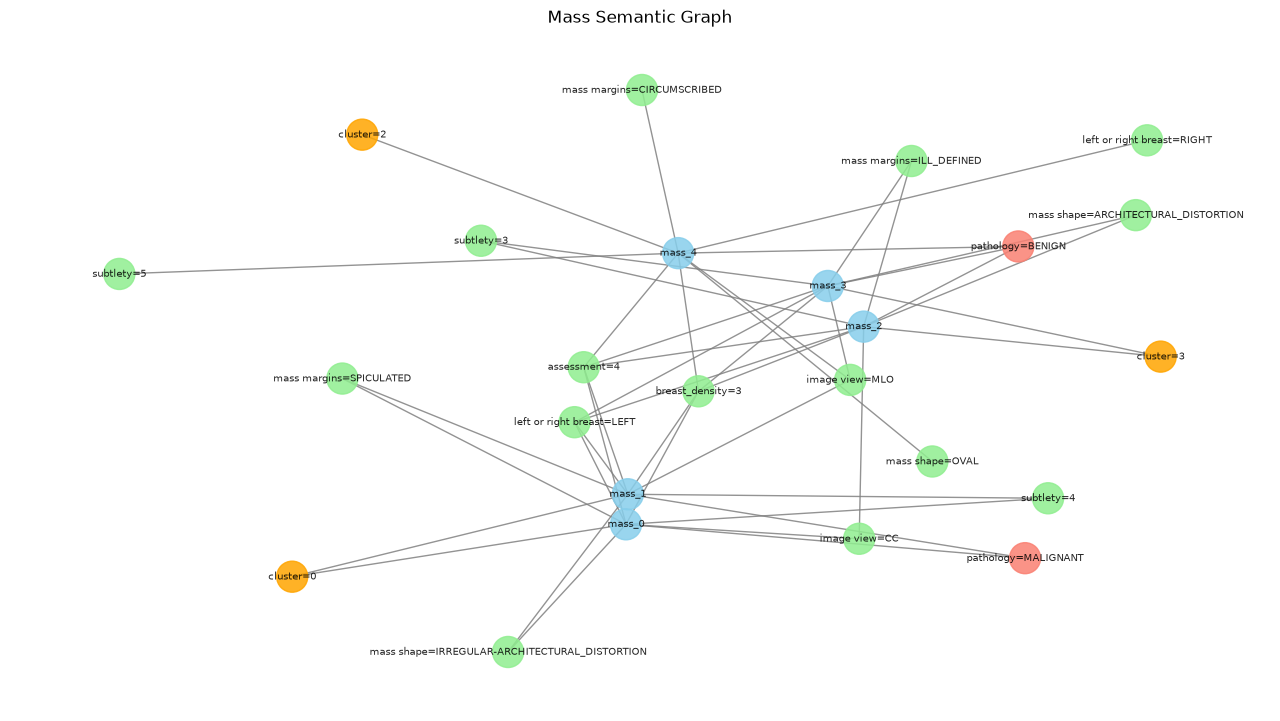

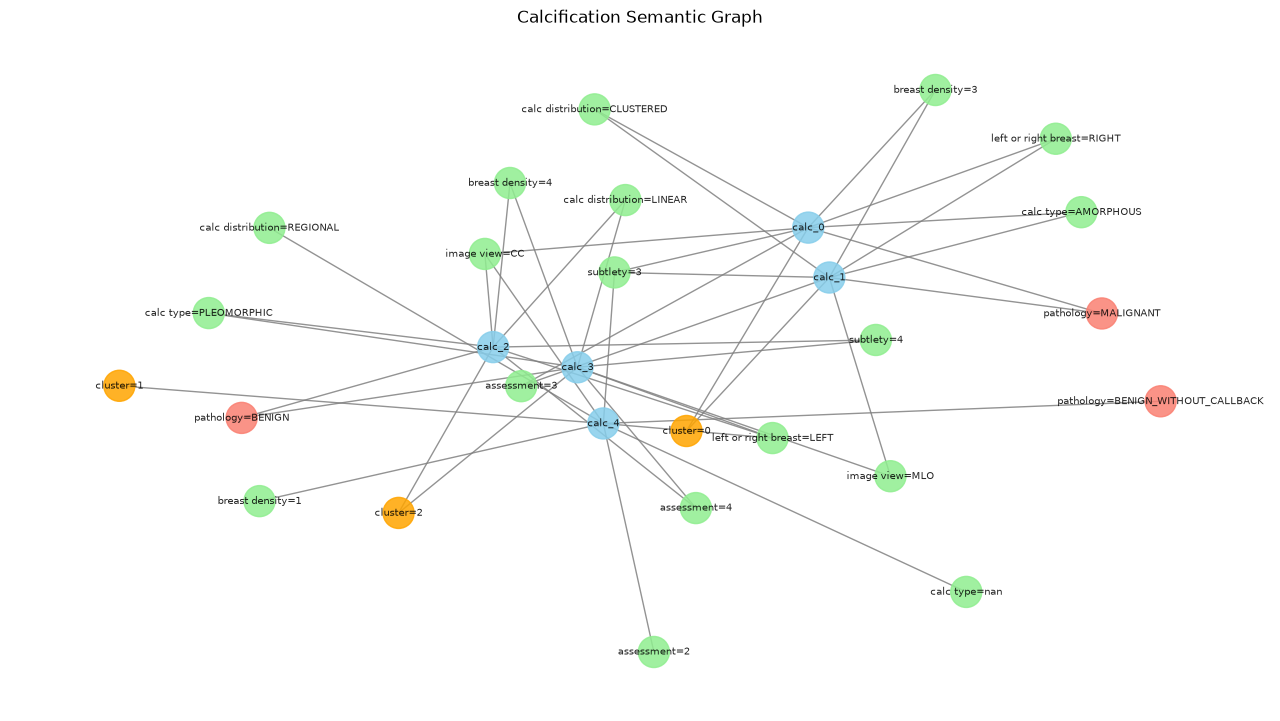

In [88]:
def visualize_sample(graph, title, n=5):
    observations = [
        node for node, data in graph.nodes(data=True)
        if data.get("node_type") == "observation"
    ][:n]

    selected_nodes = set(observations)

    for node in observations:
        selected_nodes.update(graph.neighbors(node))

    subgraph = graph.subgraph(selected_nodes)

    color_map = {
        "observation": "skyblue",
        "clinical_feature": "lightgreen",
        "pathology": "salmon",
        "cluster": "orange",
        "rule_item": "violet"
    }

    node_colors = [
        color_map.get(
            subgraph.nodes[node].get("node_type"), "gray"
        )
        for node in subgraph.nodes()
    ]

    fig, ax = plt.subplots(figsize=(14, 8))

    pos = nx.spring_layout(subgraph, seed=42, k=0.8)

    nx.draw(
        subgraph,
        pos,
        ax=ax,
        node_color=node_colors,
        node_size=500,
        font_size=7,
        with_labels=True,
        edge_color="gray",
        alpha=0.85
    )

    ax.set_title(title)
    ax.axis("off")

    fig.subplots_adjust(left=0.05, right=0.95, top=0.90, bottom=0.05)
    plt.show()


visualize_sample(mass_graph, "Mass Semantic Graph")
visualize_sample(calc_graph, "Calcification Semantic Graph")

## 16. Association Rule Selection

This section evaluates different filtering levels to identify the most relevant association rules.

Three levels are considered:

- Strong: high support, confidence, and lift.
- Interesting: moderately strong associations.
- Exploratory: less frequent patterns that may still provide useful insights.

The objective is to balance graph simplicity with knowledge preservation.

In [89]:
import pandas as pd

def classify_rules(rules):
    rules = rules.copy()

    conditions = [
        (rules["support"] >= 0.05) &
        (rules["confidence"] >= 0.80) &
        (rules["lift"] >= 2.0),

        (rules["support"] >= 0.02) &
        (rules["confidence"] >= 0.70) &
        (rules["lift"] >= 1.5),

        (rules["support"] >= 0.01) &
        (rules["confidence"] >= 0.60) &
        (rules["lift"] >= 1.2)
    ]

    levels = ["Strong", "Interesting", "Exploratory"]

    rules["level"] = "Rejected"

    for condition, level in reversed(list(zip(conditions, levels))):
        rules.loc[condition, "level"] = level

    return rules


mass_rules_classified = classify_rules(mass_rules)
calc_rules_classified = classify_rules(calc_rules)


print("MASS RULES")
print(mass_rules_classified["level"].value_counts())

print("\nCALCIFICATION RULES")
print(calc_rules_classified["level"].value_counts())

MASS RULES
level
Interesting    22
Strong          8
Name: count, dtype: int64

CALCIFICATION RULES
level
Interesting    127
Strong           2
Name: count, dtype: int64


## 17. Top Association Rules Analysis

This section examines the strongest and most interesting association rules.

Rules are ranked according to their lift and confidence values to identify potentially meaningful relationships between clinical descriptors.

In [90]:
def display_top_rules(rules, title, n=10):
    print(f"\n{title}")

    selected = rules[rules["level"] != "Rejected"].copy()

    selected = selected.sort_values(
        by=["lift", "confidence", "support"],
        ascending=False
    )

    columns = [
        "antecedents",
        "consequents",
        "support",
        "confidence",
        "lift",
        "level"
    ]

    print (selected[columns].head(n))


display_top_rules(
    mass_rules_classified,
    "TOP MASS RULES"
)

display_top_rules(
    calc_rules_classified,
    "TOP CALCIFICATION RULES"
)


TOP MASS RULES
                                         antecedents  \
0  frozenset({'subtlety_subtlety=5', 'mass margin...   
1  frozenset({'subtlety_subtlety=5', 'mass margin...   
2  frozenset({'assessment_assessment=5', 'left or...   
3  frozenset({'assessment_assessment=5', 'image v...   
4  frozenset({'subtlety_subtlety=5', 'mass margin...   
5  frozenset({'subtlety_subtlety=5', 'mass margin...   
6  frozenset({'assessment_assessment=5', 'mass sh...   
7  frozenset({'subtlety_subtlety=5', 'mass margin...   
8  frozenset({'subtlety_subtlety=5', 'assessment_...   
9  frozenset({'subtlety_subtlety=5', 'mass margin...   

                                         consequents   support  confidence  \
0             frozenset({'assessment_assessment=5'})  0.062215    0.872340   
1             frozenset({'assessment_assessment=5'})  0.059939    0.858696   
2  frozenset({'mass margins_mass margins=SPICULAT...  0.052352    0.793103   
3  frozenset({'mass margins_mass margins=SPICULAT...  0

## 18. Redundancy Analysis

This section examines repeated antecedents and consequents across association rules.

The objective is to identify recurring patterns and reduce redundant relationships before constructing the compact semantic knowledge graph.

Rules are analyzed separately for Mass and Calcification datasets.

In [91]:
def analyze_rule_patterns(rules, title):
    print(f"\n{'=' * 50}")
    print(title)
    print(f"{'=' * 50}")

    print("\nMost frequent consequents:")
    print (
        rules["consequents"]
        .value_counts()
        .head(10)
        .rename("frequency")
        .to_frame()
    )

    print("\nMost frequent antecedents:")
    print (
        rules["antecedents"]
        .value_counts()
        .head(10)
        .rename("frequency")
        .to_frame()
    )


analyze_rule_patterns(
    mass_rules_classified,
    "MASS RULE PATTERNS"
)

analyze_rule_patterns(
    calc_rules_classified,
    "CALCIFICATION RULE PATTERNS"
)


MASS RULE PATTERNS

Most frequent consequents:
                                                    frequency
consequents                                                  
frozenset({'subtlety_subtlety=5'})                         14
frozenset({'assessment_assessment=5'})                     11
frozenset({'mass margins_mass margins=SPICULATE...          4
frozenset({'assessment_assessment=4'})                      1

Most frequent antecedents:
                                                    frequency
antecedents                                                  
frozenset({'subtlety_subtlety=5', 'mass margins...          1
frozenset({'subtlety_subtlety=5', 'mass margins...          1
frozenset({'assessment_assessment=5', 'left or ...          1
frozenset({'assessment_assessment=5', 'image vi...          1
frozenset({'subtlety_subtlety=5', 'mass margins...          1
frozenset({'subtlety_subtlety=5', 'mass margins...          1
frozenset({'assessment_assessment=5', 'mass sha...      

## 19. Knowledge Pattern Selection

Rules are grouped by their consequents to identify recurring knowledge patterns.

For each consequent, the three strongest rules are selected according to lift, confidence, and support.

This approach reduces redundancy while preserving different antecedent combinations and their associated metrics.

In [92]:
def select_representative_rules(rules, top_n=3):
    selected = rules[rules["level"] != "Rejected"].copy()

    selected = selected.sort_values(
        by=["lift", "confidence", "support"],
        ascending=False
    )

    selected = (
        selected.groupby("consequents", group_keys=False)
        .head(top_n)
        .reset_index(drop=True)
    )

    return selected


mass_selected_rules = select_representative_rules(
    mass_rules_classified
)

calc_selected_rules = select_representative_rules(
    calc_rules_classified
)


print("Mass selected rules:", len(mass_selected_rules))
print("Calcification selected rules:", len(calc_selected_rules))

print("\nMass knowledge patterns:")
print (mass_selected_rules[
    ["antecedents", "consequents", "support",
     "confidence", "lift", "level"]
])

print("\nCalcification knowledge patterns:")
print (calc_selected_rules[
    ["antecedents", "consequents", "support",
     "confidence", "lift", "level"]
])

Mass selected rules: 10
Calcification selected rules: 11

Mass knowledge patterns:
                                         antecedents  \
0  frozenset({'subtlety_subtlety=5', 'mass margin...   
1  frozenset({'subtlety_subtlety=5', 'mass margin...   
2  frozenset({'assessment_assessment=5', 'left or...   
3  frozenset({'assessment_assessment=5', 'image v...   
4  frozenset({'subtlety_subtlety=5', 'mass margin...   
5  frozenset({'assessment_assessment=5', 'mass sh...   
6  frozenset({'breast_density_breast_density=1', ...   
7  frozenset({'assessment_assessment=5', 'left or...   
8  frozenset({'assessment_assessment=5', 'breast_...   
9  frozenset({'left or right breast_left or right...   

                                         consequents   support  confidence  \
0             frozenset({'assessment_assessment=5'})  0.062215    0.872340   
1             frozenset({'assessment_assessment=5'})  0.059939    0.858696   
2  frozenset({'mass margins_mass margins=SPICULAT...  0.052352    

## 20. Compact Semantic Knowledge Graph Construction

This section builds a compact knowledge graph from the selected association rules.

Each rule is represented by an intermediate rule node connected to its antecedent and consequent items.

This structure preserves multi-item antecedents and stores support, confidence, lift, and selection level as rule metadata.

The resulting graphs focus on selected knowledge patterns rather than individual observations.

In [93]:
import ast
import networkx as nx


def parse_frozenset(value):
    node = ast.parse(value, mode="eval").body

    if (
        isinstance(node, ast.Call)
        and isinstance(node.func, ast.Name)
        and node.func.id == "frozenset"
        and len(node.args) == 1
    ):
        return ast.literal_eval(node.args[0])

    raise ValueError("Unexpected association rule format")


def build_compact_graph(rules, prefix):
    graph = nx.DiGraph()

    for i, row in rules.iterrows():
        rule_node = f"{prefix}_rule_{i}"

        graph.add_node(
            rule_node,
            node_type="association_rule",
            support=float(row["support"]),
            confidence=float(row["confidence"]),
            lift=float(row["lift"]),
            level=row["level"]
        )

        antecedents = parse_frozenset(row["antecedents"])
        consequents = parse_frozenset(row["consequents"])

        for item in antecedents:
            feature_node = f"{prefix}_feature_{item}"

            graph.add_node(
                feature_node,
                node_type="clinical_feature",
                label=item
            )

            graph.add_edge(
                feature_node,
                rule_node,
                relationship="antecedent"
            )

        for item in consequents:
            feature_node = f"{prefix}_feature_{item}"

            graph.add_node(
                feature_node,
                node_type="clinical_feature",
                label=item
            )

            graph.add_edge(
                rule_node,
                feature_node,
                relationship="consequent"
            )

    return graph


mass_knowledge_graph = build_compact_graph(
    mass_selected_rules, "mass"
)

calc_knowledge_graph = build_compact_graph(
    calc_selected_rules, "calc"
)


print("Mass Knowledge Graph")
print("Nodes:", mass_knowledge_graph.number_of_nodes())
print("Edges:", mass_knowledge_graph.number_of_edges())

print("\nCalcification Knowledge Graph")
print("Nodes:", calc_knowledge_graph.number_of_nodes())
print("Edges:", calc_knowledge_graph.number_of_edges())

Mass Knowledge Graph
Nodes: 21
Edges: 36

Calcification Knowledge Graph
Nodes: 25
Edges: 36


## 21. Compact Knowledge Graph Visualization

The following visualization presents the selected association rules as compact semantic graphs.

Clinical feature nodes represent rule items, while rule nodes preserve the association metrics and the direction between antecedents and consequents.

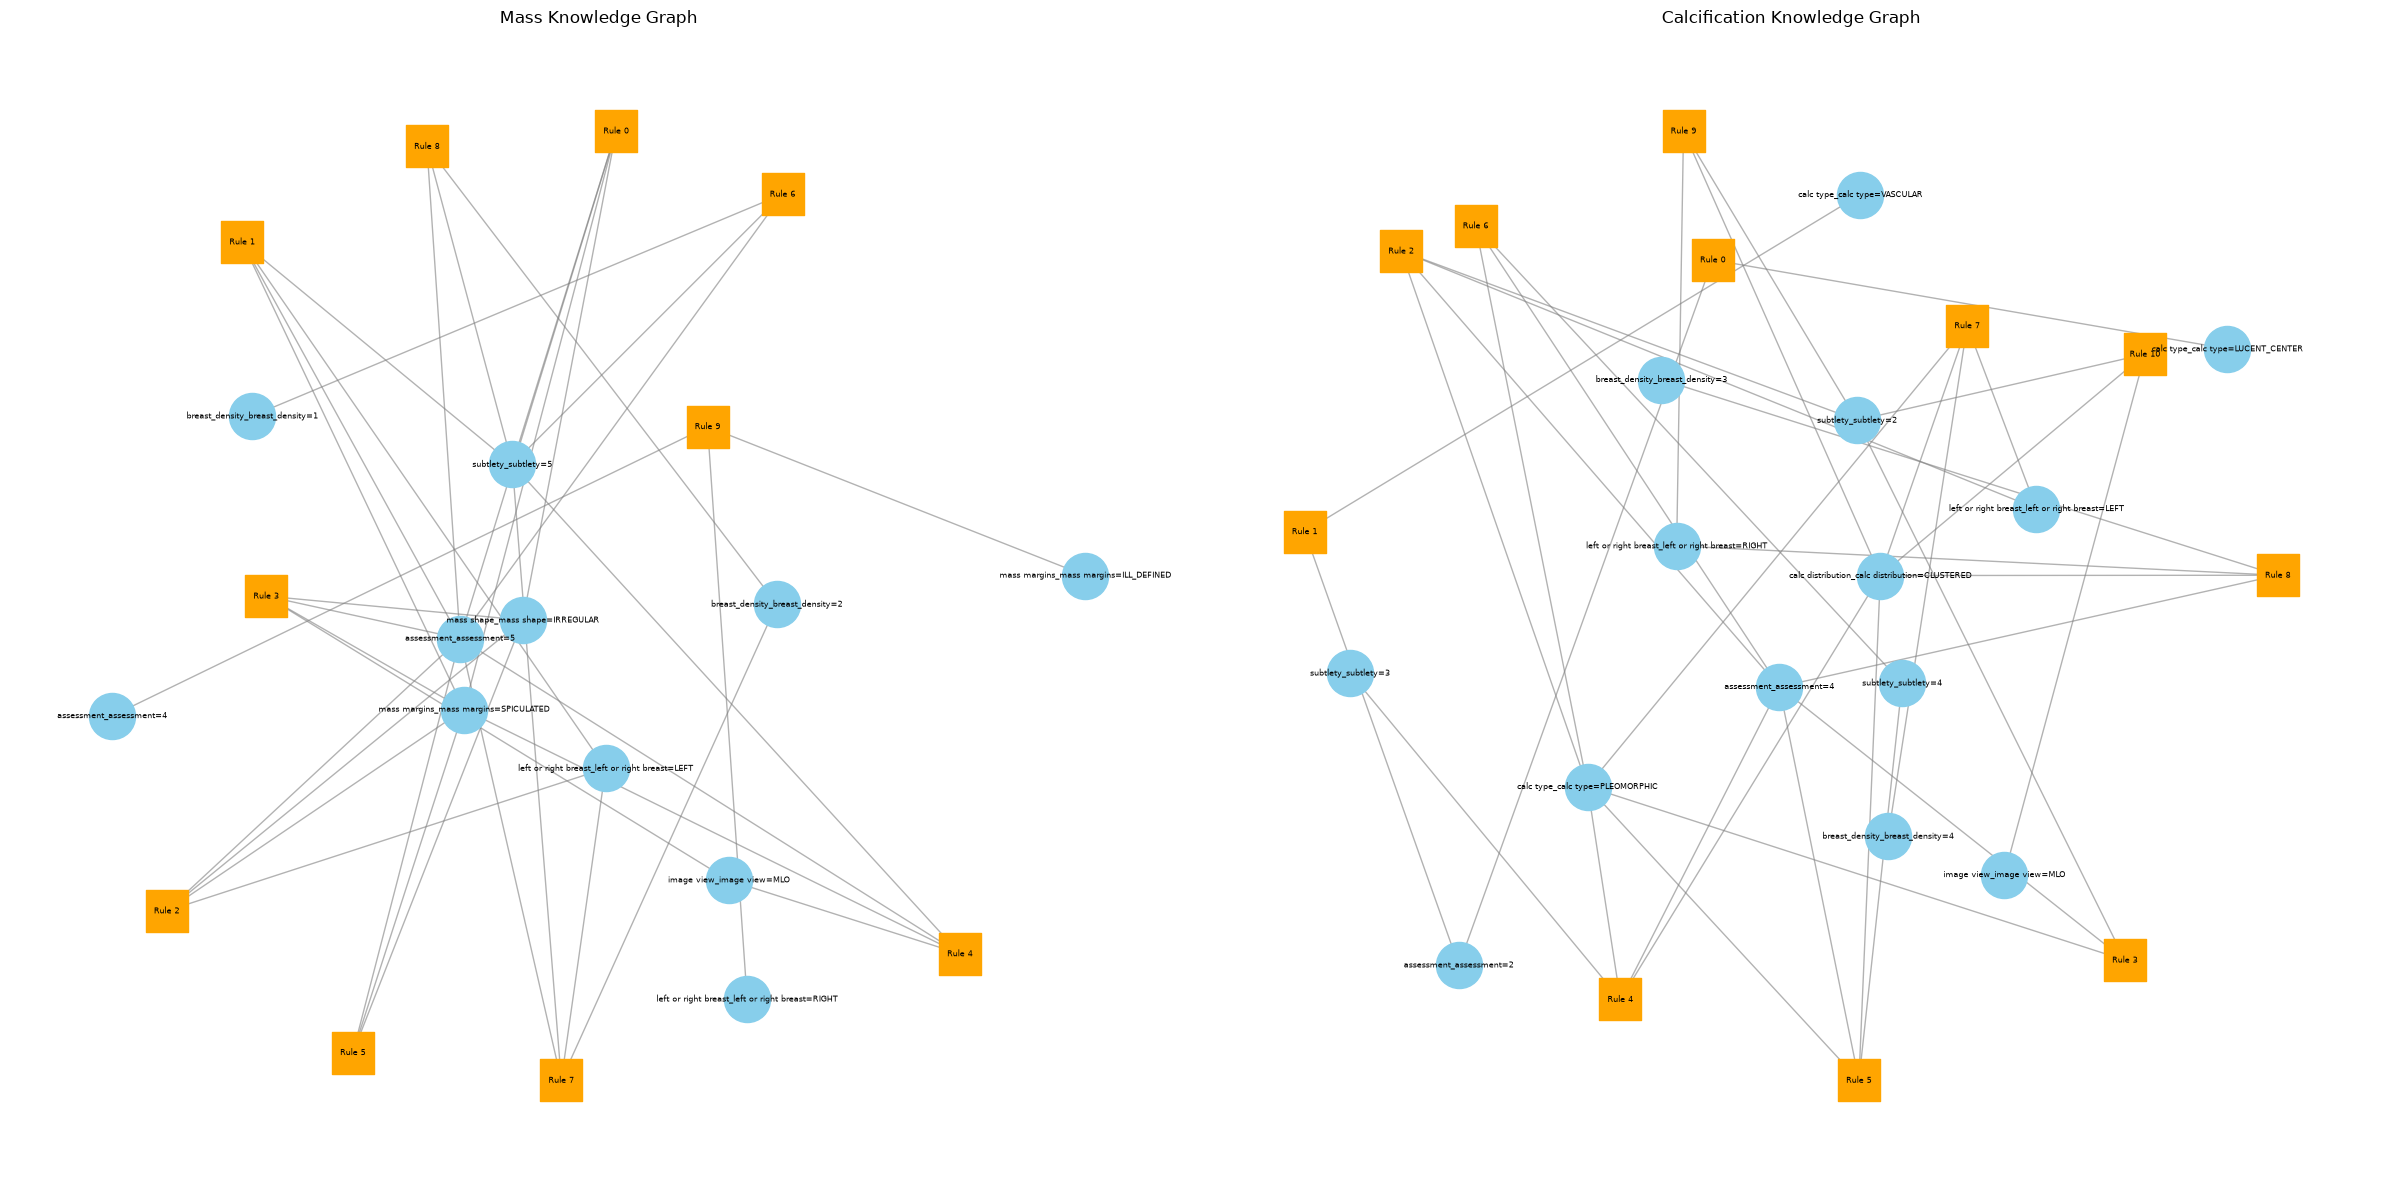

In [94]:
def visualize_knowledge_graph(graph, title):
    pos = nx.spring_layout(graph, seed=42, k=1.2)

    feature_nodes = [
        n for n, d in graph.nodes(data=True)
        if d["node_type"] == "clinical_feature"
    ]

    rule_nodes = [
        n for n, d in graph.nodes(data=True)
        if d["node_type"] == "association_rule"
    ]

    plt.figure(figsize=(16, 12))

    nx.draw_networkx_nodes(
        graph, pos,
        nodelist=feature_nodes,
        node_color="skyblue",
        node_size=1300
    )

    nx.draw_networkx_nodes(
        graph, pos,
        nodelist=rule_nodes,
        node_color="orange",
        node_shape="s",
        node_size=1100
    )

    labels = {
        n: d.get("label", f"Rule {n.split('_')[-1]}")
        for n, d in graph.nodes(data=True)
    }

    nx.draw_networkx_labels(
        graph, pos,
        labels=labels,
        font_size=7
    )

    nx.draw_networkx_edges(
        graph, pos,
        arrows=True,
        arrowsize=12,
        edge_color="gray",
        alpha=0.6
    )

    plt.title(title)
    plt.axis("off")
    plt.show()


fig, axes = plt.subplots(1, 2, figsize=(24, 12))

for ax, graph, title in [
    (axes[0], mass_knowledge_graph, "Mass Knowledge Graph"),
    (axes[1], calc_knowledge_graph, "Calcification Knowledge Graph")
]:
    pos = nx.spring_layout(graph, seed=42, k=1.2)

    feature_nodes = [
        n for n, d in graph.nodes(data=True)
        if d["node_type"] == "clinical_feature"
    ]

    rule_nodes = [
        n for n, d in graph.nodes(data=True)
        if d["node_type"] == "association_rule"
    ]

    nx.draw_networkx_nodes(
        graph, pos, ax=ax,
        nodelist=feature_nodes,
        node_color="skyblue",
        node_size=1100
    )

    nx.draw_networkx_nodes(
        graph, pos, ax=ax,
        nodelist=rule_nodes,
        node_color="orange",
        node_shape="s",
        node_size=900
    )

    labels = {
        n: d.get("label", f"Rule {n.split('_')[-1]}")
        for n, d in graph.nodes(data=True)
    }

    nx.draw_networkx_labels(
        graph, pos, labels=labels,
        font_size=6, ax=ax
    )

    nx.draw_networkx_edges(
        graph, pos, ax=ax,
        arrows=True, arrowsize=10,
        edge_color="gray", alpha=0.6
    )

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 22. Association Rules Interpretation

This section presents the selected association rules in a readable format.

For each rule, we display:
- **Antecedents:** the conditions of the rule.
- **Consequents:** the resulting associated item.
- **Support:** the proportion of observations containing both sides.
- **Confidence:** how frequently the consequent appears when the antecedents are present.
- **Lift:** the strength of the association compared with the expected frequency under independence.

These metrics help assess and interpret the selected knowledge patterns.

In [95]:
def format_item(item):
    if "_" in item:
        feature, value = item.split("_", 1)
        return f"{feature}: {value}"
    return item


def prepare_rules_table(rules):
    rows = []

    for _, row in rules.iterrows():
        antecedents = parse_frozenset(row["antecedents"])
        consequents = parse_frozenset(row["consequents"])

        rows.append({
            "Antecedents": " AND ".join(
                sorted(format_item(x) for x in antecedents)
            ),
            "Consequents": " AND ".join(
                sorted(format_item(x) for x in consequents)
            ),
            "Support": round(row["support"], 3),
            "Confidence": round(row["confidence"], 3),
            "Lift": round(row["lift"], 3),
            "Level": row["level"]
        })

    return pd.DataFrame(rows)


mass_interpreted_rules = prepare_rules_table(mass_selected_rules)
calc_interpreted_rules = prepare_rules_table(calc_selected_rules)

print("MASS — Selected Knowledge Patterns")
print (mass_interpreted_rules)

print("CALCIFICATION — Selected Knowledge Patterns")
print (calc_interpreted_rules)

MASS — Selected Knowledge Patterns
                                         Antecedents  \
0  mass margins: mass margins=SPICULATED AND mass...   
1  left or right breast: left or right breast=LEF...   
2  assessment: assessment=5 AND left or right bre...   
3  assessment: assessment=5 AND image view: image...   
4  image view: image view=MLO AND mass margins: m...   
5  assessment: assessment=5 AND mass shape: mass ...   
6  assessment: assessment=5 AND breast: density_b...   
7  assessment: assessment=5 AND breast: density_b...   
8  assessment: assessment=5 AND breast: density_b...   
9  left or right breast: left or right breast=RIG...   

                             Consequents  Support  Confidence   Lift  \
0               assessment: assessment=5    0.062       0.872  3.845   
1               assessment: assessment=5    0.060       0.859  3.785   
2  mass margins: mass margins=SPICULATED    0.052       0.793  3.720   
3  mass margins: mass margins=SPICULATED    0.053       0.78

## 23. Exporting Knowledge Graphs and Selected Rules

The compact knowledge graphs and interpreted association rules are exported for reuse in the final prototype.

The graph files preserve their nodes, relationships, and metadata, while the CSV files provide readable tables of the selected knowledge patterns.

In [96]:
import os
import networkx as nx

os.makedirs("../data/processed", exist_ok=True)

# Export knowledge graphs
nx.write_graphml(
    mass_knowledge_graph,
    "../data/processed/mass_knowledge_graph.graphml"
)

nx.write_graphml(
    calc_knowledge_graph,
    "../data/processed/calc_knowledge_graph.graphml"
)

# Export interpreted association rules
mass_interpreted_rules.to_csv(
    "../data/processed/mass_selected_rules.csv",
    index=False
)

calc_interpreted_rules.to_csv(
    "../data/processed/calc_selected_rules.csv",
    index=False
)

print("Knowledge graphs and selected rules exported successfully.")

Knowledge graphs and selected rules exported successfully.


## 24. Improved Knowledge Graph Visualization

This section improves graph readability by using shortened node labels, larger figures, and increased spacing.

Detailed rule information remains available in the association rules tables.

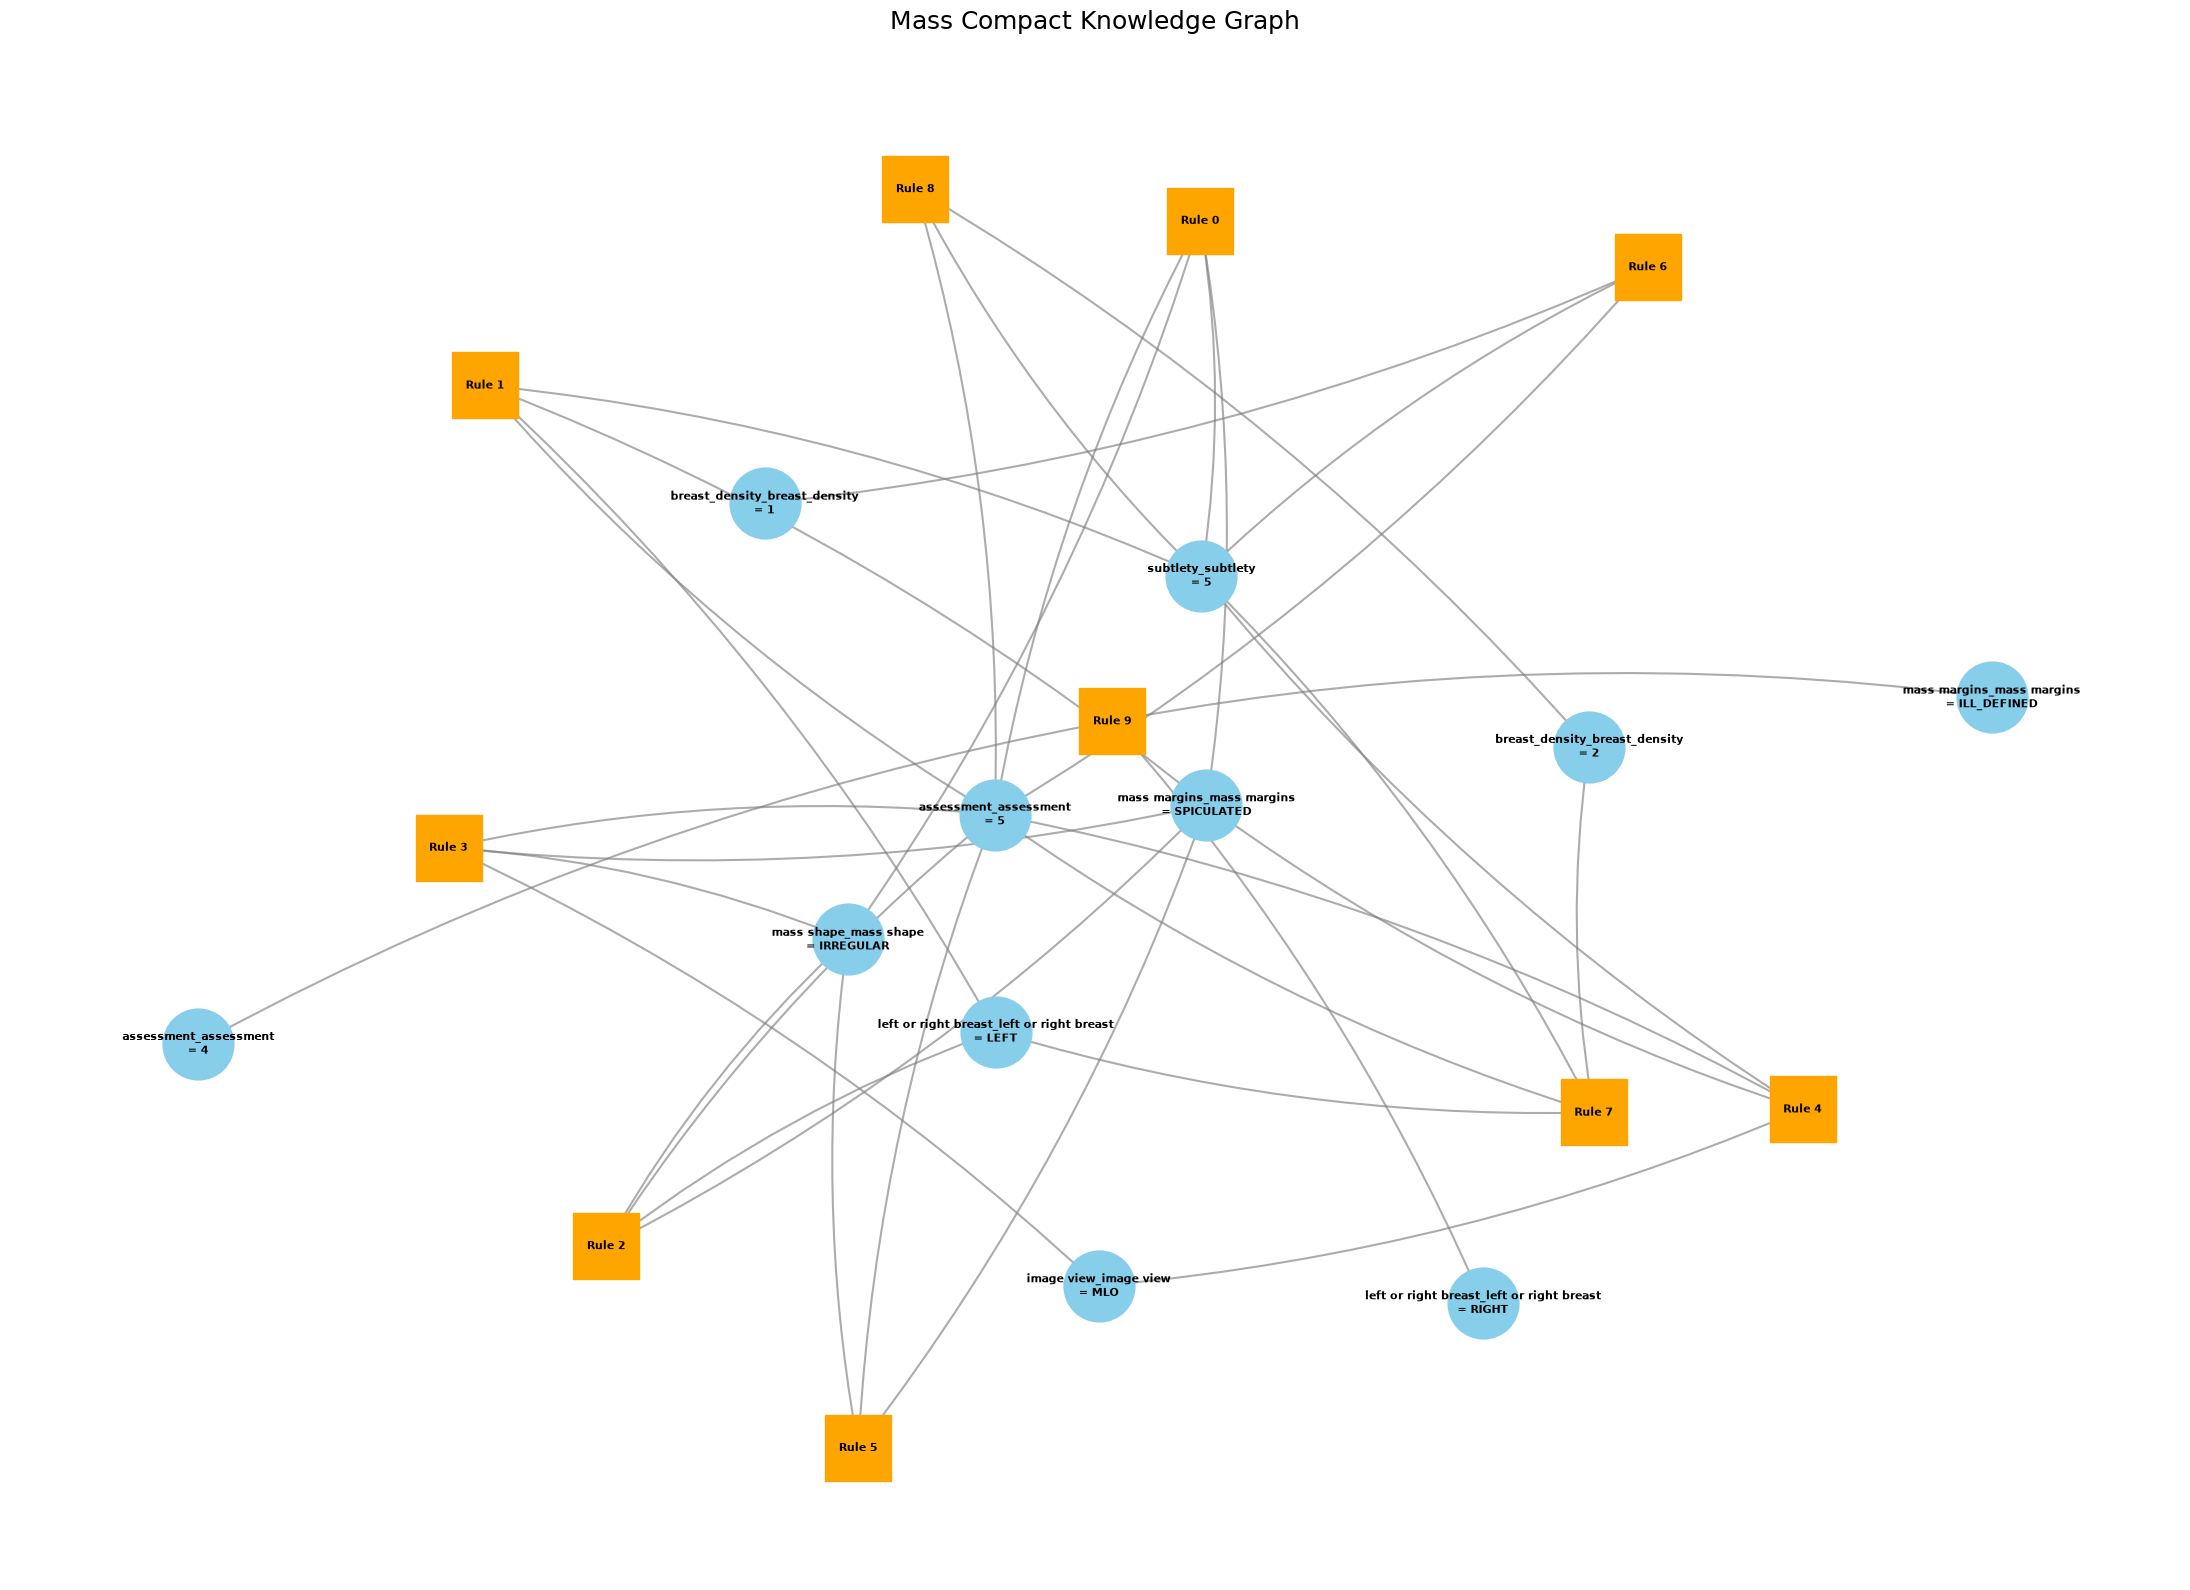

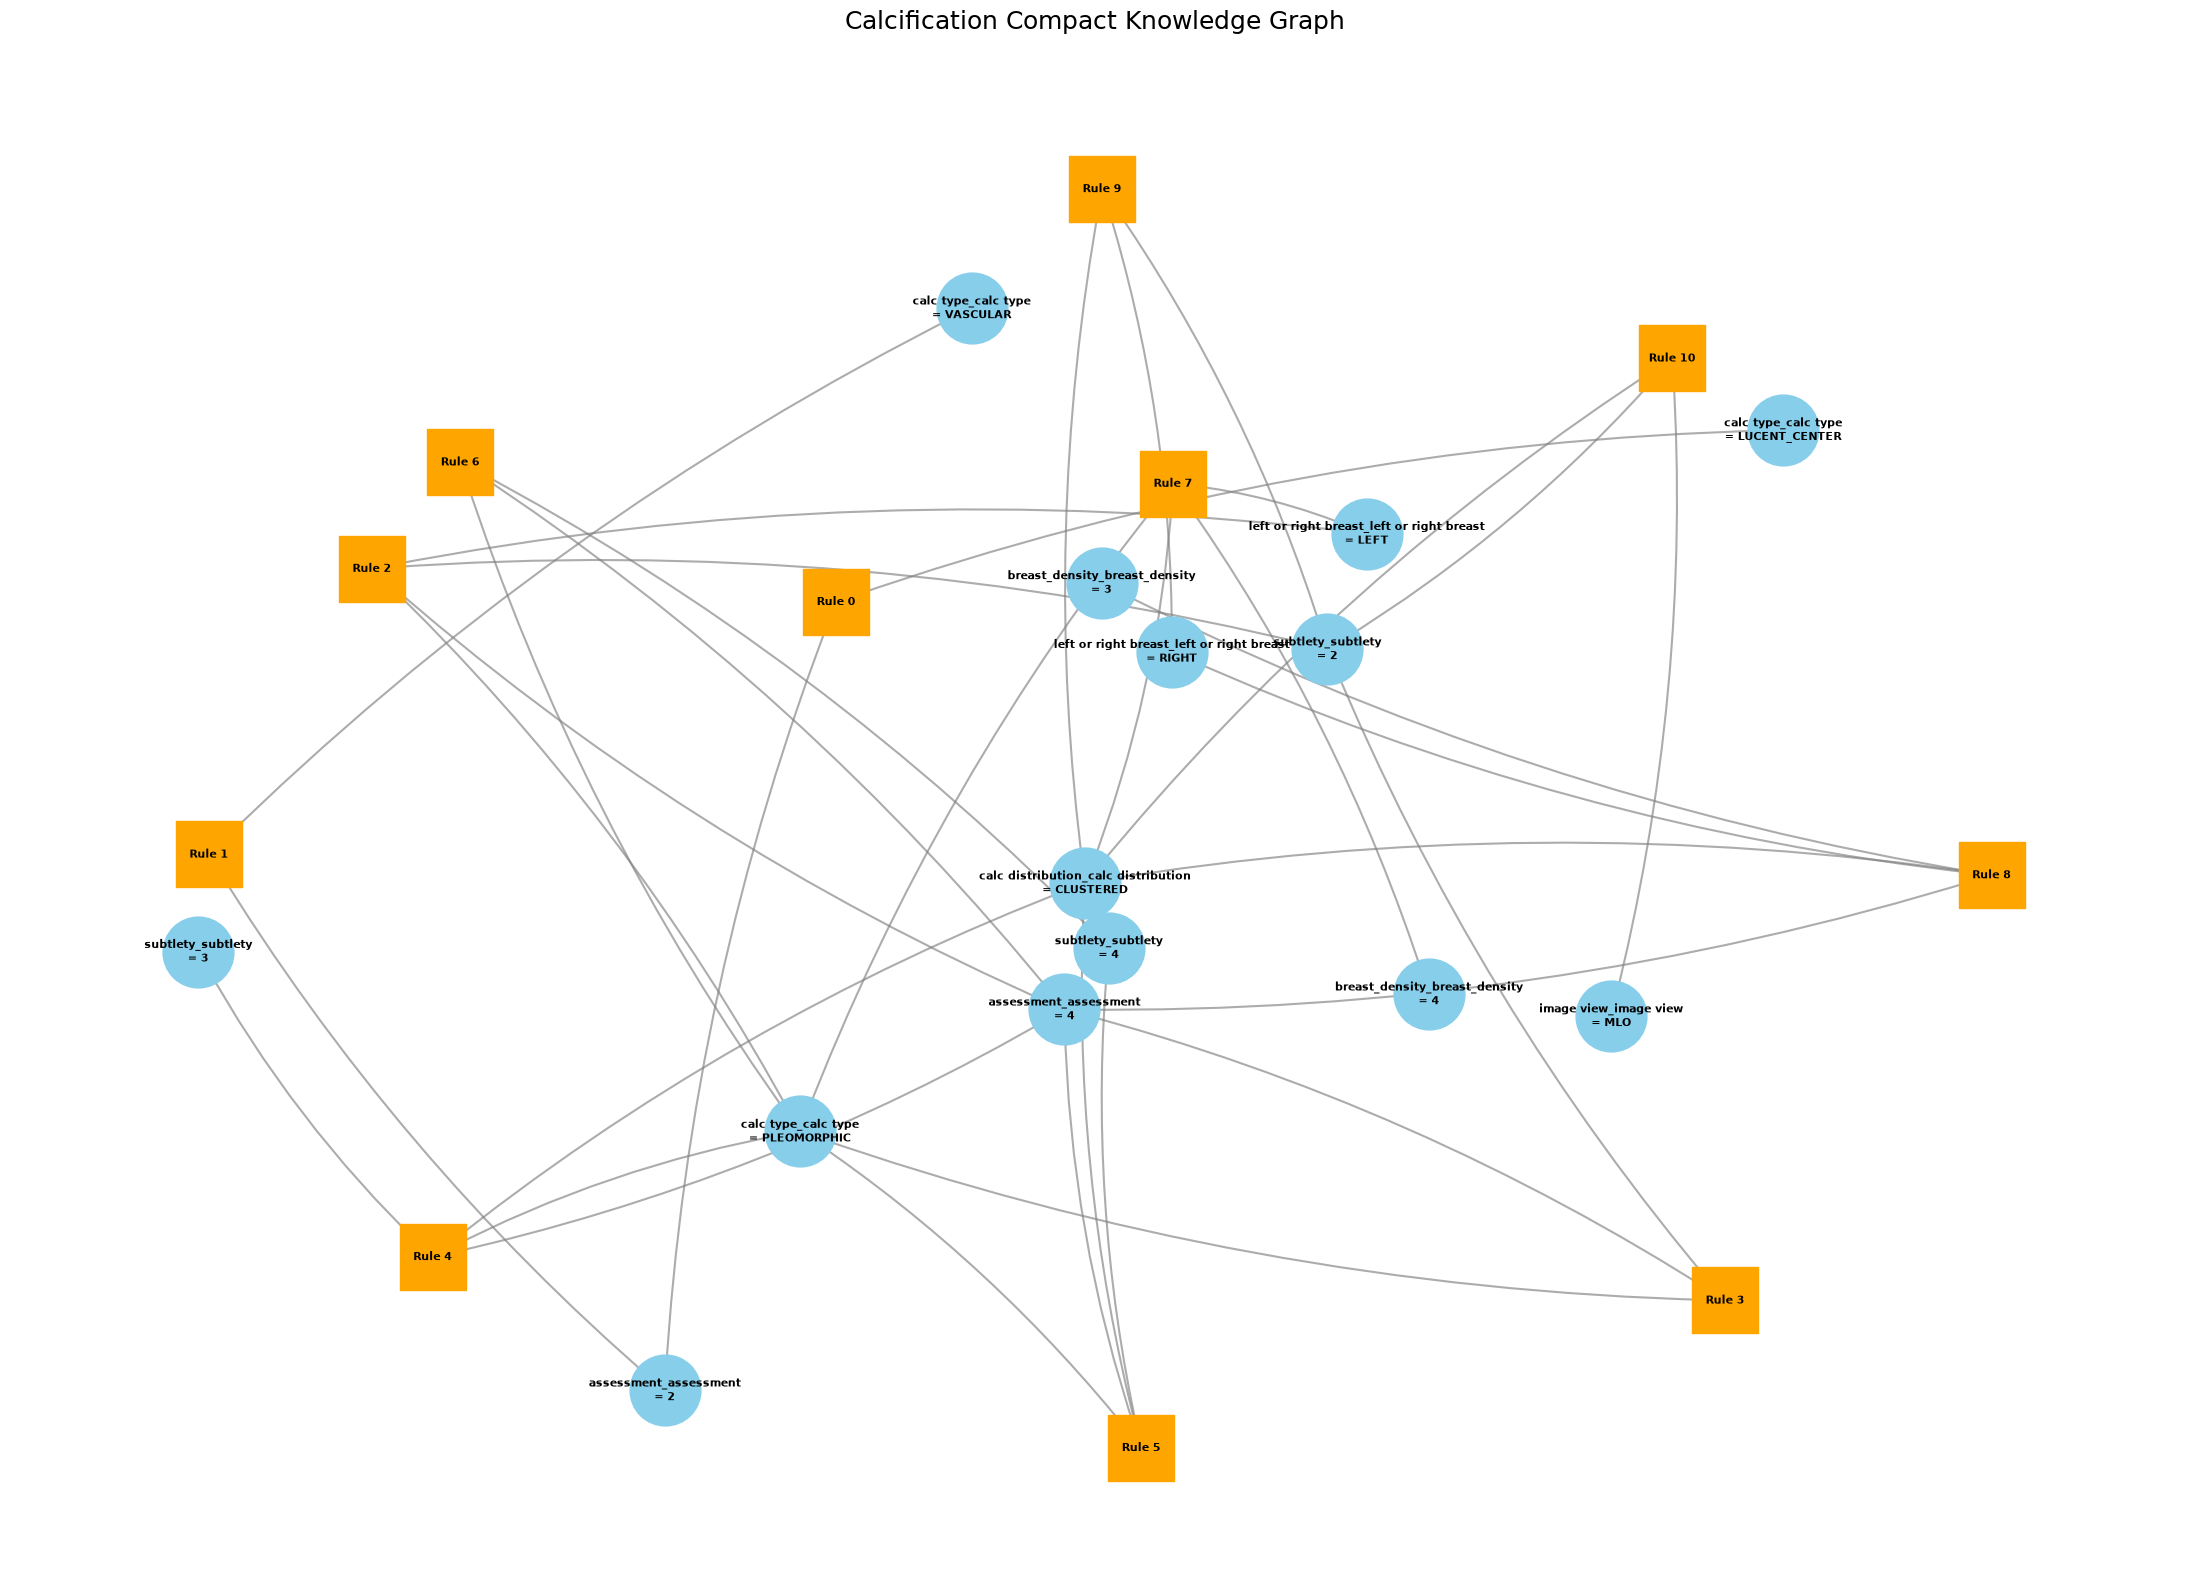

In [97]:
def short_label(data, node):
    if data["node_type"] == "association_rule":
        return f"Rule {node.split('_')[-1]}"

    label = data.get("label", node)

    if "=" in label:
        feature, value = label.split("=", 1)
        return f"{feature}\n= {value}"

    return label


def visualize_compact_graph(graph, title):
    fig, ax = plt.subplots(figsize=(22, 16))

    pos = nx.spring_layout(
        graph,
        seed=42,
        k=2.5,
        iterations=150
    )

    feature_nodes = [
        n for n, d in graph.nodes(data=True)
        if d["node_type"] == "clinical_feature"
    ]

    rule_nodes = [
        n for n, d in graph.nodes(data=True)
        if d["node_type"] == "association_rule"
    ]

    labels = {
        n: short_label(data, n)
        for n, data in graph.nodes(data=True)
    }

    nx.draw_networkx_nodes(
        graph, pos, ax=ax,
        nodelist=feature_nodes,
        node_color="skyblue",
        node_size=2600
    )

    nx.draw_networkx_nodes(
        graph, pos, ax=ax,
        nodelist=rule_nodes,
        node_color="orange",
        node_shape="s",
        node_size=2200
    )

    nx.draw_networkx_labels(
        graph, pos, labels=labels, ax=ax,
        font_size=8,
        font_weight="bold"
    )

    nx.draw_networkx_edges(
        graph, pos, ax=ax,
        arrows=True,
        arrowsize=18,
        width=1.5,
        edge_color="gray",
        alpha=0.65,
        connectionstyle="arc3,rad=0.08"
    )

    ax.set_title(title, fontsize=18, pad=20)
    ax.axis("off")

    plt.tight_layout()
    plt.show()


visualize_compact_graph(
    mass_knowledge_graph,
    "Mass Compact Knowledge Graph"
)

visualize_compact_graph(
    calc_knowledge_graph,
    "Calcification Compact Knowledge Graph"
)

## 25. Conclusion

This notebook focused on transforming the knowledge extracted from clinical descriptors into structured semantic representations.

The main achievements include:

- Construction of detailed knowledge graphs for Mass and Calcification datasets.
- Integration of clinical features, pathology categories, clustering results, and association rules.
- Selection of representative association rules based on support, confidence, and lift.
- Construction of compact semantic knowledge graphs to improve interpretability.
- Visualization and export of the resulting graphs and knowledge patterns.

The exported GraphML and CSV files will serve as inputs for the final interactive web interface.

This completes the semantic graph construction stage and provides a structured knowledge representation for the next development phase.